# Diffusion Inference Optimization and Deployment

This standalone notebook benchmarks a pretrained text-to-image pipeline for latency, throughput, memory, and deployment trade-offs. It downloads its own model; it does not depend on earlier notebooks or local checkpoints.

**Inference engineering overview.** Latency is the time for one generation request; throughput is how many images complete per second, often measured across a batch. Cold-start time includes weight downloads/loading and runtime initialization; warm inference measures repeat generation after warm-up. Diffusion differs from one-pass neural inference because the denoiser is invoked repeatedly at each scheduler step, followed by VAE decoding. GPU memory must hold weights, activations, and intermediate latents; batching can improve utilization while increasing memory and request latency. Reduced precision usually cuts memory and may improve speed, with numerical differences. A local generation timer is not full request latency: production also includes queue wait, validation, preprocessing, encoding, network transfer, and storage.

The default is [`stabilityai/sd-turbo`](https://huggingface.co/stabilityai/sd-turbo), compatible with Diffusers and available in safetensors format. Its model card currently lists the CreativeML OpenRAIL-M license and points to Stability AI terms for commercial use. Review the current model card, license, and acceptable-use terms before deployment. The repository is currently publicly viewable; access, authentication requirements, and license terms may change. This distilled model is designed for low step counts and recommends guidance scale zero. Hardware and download requirements vary; CPU is included as a slow fallback.

## 1. Install dependencies

Install Diffusers and the supporting inference and optional API packages. Existing Colab PyTorch is preserved. If installation changes a package already imported in the runtime, restart the runtime and continue at the imports cell.

In [12]:
%pip install -q "diffusers>=0.30" "transformers>=4.41" accelerate safetensors pillow matplotlib fastapi uvicorn
%pip install -U torchao diffusers


## 2. Environment and configuration

The model is preferred at 512?512. A typical benchmark batch is small. GPU BF16 is selected if the device supports it; otherwise FP16 is used, and CPU falls back to FP32. An FP32 GPU trial is attempted only when supported by CUDA and may be skipped if memory is insufficient.

In [13]:
# Fix version mismatch dynamically
import sys
import subprocess

try:
    from diffusers import DiffusionPipeline, DDIMScheduler
except (ImportError, RuntimeError) as e:
    print("Detected library mismatch (torchao and diffusers). Upgrading and installing compatible versions...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-U", "--quiet", "diffusers", "torchao"])
    # Reload site packages so the environment sees the newly upgraded packages
    import site
    from importlib import reload
    reload(site)

import asyncio
import gc
import io
import statistics
import time
from pathlib import Path
from typing import Optional
import matplotlib.pyplot as plt
import torch
import diffusers
import transformers
from PIL import Image
from diffusers import DiffusionPipeline, DDIMScheduler
from tqdm.auto import tqdm

print("PyTorch:",torch.__version__); print("Diffusers:",diffusers.__version__); print("Transformers:",transformers.__version__)
print("CUDA runtime:",torch.version.cuda,"available:",torch.cuda.is_available())
if torch.cuda.is_available():
    device=torch.device("cuda"); props=torch.cuda.get_device_properties(0)
    print("GPU:",torch.cuda.get_device_name(0),f"| memory={props.total_memory/1024**3:.1f} GiB")
else:
    device=torch.device("cpu"); print("CPU inference is supported but can be significantly slower.")

if device.type=="cuda":
    BASE_DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
else:
    BASE_DTYPE=torch.float32
CONFIG={
    "MODEL_ID":"stabilityai/sd-turbo",
    "prompt":"A quiet alpine lake at sunrise, cinematic landscape photography, detailed natural light",
    "negative_prompt":"blurry, low quality, text, watermark",
    "height":512,"width":512,"seed":2026,"num_inference_steps":4,"guidance_scale":0.0,
    "batch_sizes":[1,2,4],"step_counts":[1,2,4],"repetitions":3,"warmup_runs":1,
    "output_dir":"inference_optimization_outputs","run_cpu_offload_experiment":False,
}
assert CONFIG["height"]%8==0 and CONFIG["width"]%8==0
print("Model:",CONFIG["MODEL_ID"],"| device:",device,"| baseline dtype:",BASE_DTYPE)
print("Workload:",CONFIG["width"],"x",CONFIG["height"],"| steps:",CONFIG["num_inference_steps"],"| batches:",CONFIG["batch_sizes"])

PyTorch: 2.11.0+cu130
Diffusers: 0.41.0
Transformers: 5.20.1
CUDA runtime: 13.0 available: True
GPU: Tesla T4 | memory=14.6 GiB
Model: stabilityai/sd-turbo | device: cuda | baseline dtype: torch.bfloat16
Workload: 512 x 512 | steps: 4 | batches: [1, 2, 4]


## 3. Load model and measure cold start

Download/loading time is measured separately and not mixed into generation timings. We use safe weight formats, the selected dtype, and move the pipeline to the selected device. Enable model CPU offload only on CUDA; it trades additional transfers/latency for reduced VRAM. Error messages include next steps for gated repositories, package issues, and out-of-memory failures.

In [3]:
def load_pipeline(dtype:torch.dtype, offload:bool=False):
    try:
        loaded=DiffusionPipeline.from_pretrained(CONFIG["MODEL_ID"],torch_dtype=dtype,
            use_safetensors=True,low_cpu_mem_usage=True)
        if offload:
            if device.type!="cuda": raise ValueError("Model CPU offload requires CUDA.")
            loaded.enable_model_cpu_offload()
        else:
            loaded.to(device)
        return loaded
    except Exception as exc:
        raise RuntimeError(
            f"Loading {CONFIG['MODEL_ID']!r} failed. Verify the model ID and network; open the model page and accept any required terms; "
            "authenticate if gated; check compatible diffusers/transformers versions; and use CPU offload or a smaller workload if RAM/VRAM is insufficient. "
            f"Original error: {exc!r}"
        ) from exc

load_start=time.perf_counter()
pipe=load_pipeline(BASE_DTYPE)
load_seconds=time.perf_counter()-load_start
original_scheduler=pipe.scheduler
original_scheduler_config=original_scheduler.config
print(f"Model load time (download + initialization): {load_seconds:.2f}s")
print("Pipeline:",type(pipe).__name__,"scheduler:",type(pipe.scheduler).__name__)
print("Device:",device,"dtype:",BASE_DTYPE,"U-Net config:",getattr(pipe.unet,"config",None))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Model load time (download + initialization): 75.17s
Pipeline: StableDiffusionPipeline scheduler: EulerDiscreteScheduler
Device: cuda dtype: torch.bfloat16 U-Net config: FrozenDict({'sample_size': 64, 'in_channels': 4, 'out_channels': 4, 'center_input_sample': False, 'flip_sin_to_cos': True, 'freq_shift': 0, 'down_block_types': ['CrossAttnDownBlock2D', 'CrossAttnDownBlock2D', 'CrossAttnDownBlock2D', 'DownBlock2D'], 'mid_block_type': 'UNetMidBlock2DCrossAttn', 'up_block_types': ['UpBlock2D', 'CrossAttnUpBlock2D', 'CrossAttnUpBlock2D', 'CrossAttnUpBlock2D'], 'only_cross_attention': False, 'block_out_channels': [320, 640, 1280, 1280], 'layers_per_block': 2, 'downsample_padding': 1, 'mid_block_scale_factor': 1, 'dropout': 0.0, 'act_fn': 'silu', 'norm_num_groups': 32, 'norm_eps': 1e-05, 'cross_attention_dim': 1024, 'transformer_layers_per_block': 1, 'reverse_transformer_layers_per_block': None, 'encoder_hid_dim': None, 'encoder_hid_dim_type': None, 'attention_head_dim': [5, 10, 20, 20], 'num

## 4. Reusable benchmark helper and baseline

The helper runs warm-ups, synchronizes CUDA before and after each timed call, resets peak GPU memory counters, repeats the exact workload with a fixed seed, and reports median latency. Throughput is batch size divided by median batch latency. GPU peak memory includes resident model weights plus temporary allocations, so compare it only under consistent load conditions. These numbers do not include request queueing or network costs.

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

Baseline | median=2.72s | per image=2.72s | throughput=0.367 img/s
Model load: 75.17s | warm-up: 4.21s | timed repetitions: 3
Peak allocated/reserved GiB: 3.8980565071105957 4.9375


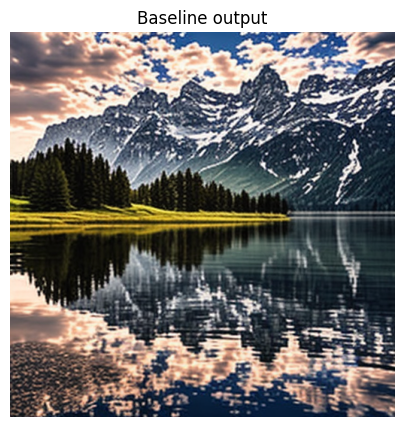

In [4]:
def make_generator(seed:int)->torch.Generator:
    g=torch.Generator(device=device); g.manual_seed(int(seed)); return g

def sync_cuda():
    if device.type=="cuda": torch.cuda.synchronize()

def run_once(pipeline,prompt:str,*,seed:int,steps:int,guidance:float,batch_size:int):
    args={"prompt":prompt,"height":CONFIG["height"],"width":CONFIG["width"],
          "num_inference_steps":int(steps),"guidance_scale":float(guidance),
          "num_images_per_prompt":int(batch_size),"generator":make_generator(seed)}
    args["negative_prompt"]=CONFIG["negative_prompt"]
    with torch.inference_mode(): return pipeline(**args).images

def benchmark(pipeline,*,prompt:Optional[str]=None,seed:Optional[int]=None,
              steps:Optional[int]=None,guidance:Optional[float]=None,batch_size:int=1,
              repetitions:Optional[int]=None,warmup_runs:Optional[int]=None):
    prompt=prompt or CONFIG["prompt"]; seed=CONFIG["seed"] if seed is None else int(seed)
    steps=CONFIG["num_inference_steps"] if steps is None else int(steps)
    guidance=CONFIG["guidance_scale"] if guidance is None else float(guidance)
    repetitions=CONFIG["repetitions"] if repetitions is None else int(repetitions)
    warmup_runs=CONFIG["warmup_runs"] if warmup_runs is None else int(warmup_runs)
    sync_cuda(); warm_start=time.perf_counter()
    for _ in range(warmup_runs):
        _=run_once(pipeline,prompt,seed=seed,steps=steps,guidance=guidance,batch_size=batch_size)
    sync_cuda(); warmup_seconds=time.perf_counter()-warm_start
    if device.type=="cuda": torch.cuda.reset_peak_memory_stats()
    durations=[]; images=None
    for _ in range(repetitions):
        sync_cuda(); start=time.perf_counter()
        images=run_once(pipeline,prompt,seed=seed,steps=steps,guidance=guidance,batch_size=batch_size)
        sync_cuda(); durations.append(time.perf_counter()-start)
    median=statistics.median(durations)
    return {"images":images,"median_seconds":median,"warmup_seconds":warmup_seconds,"per_image_seconds":median/batch_size,
            "images_per_second":batch_size/median,"repetitions":repetitions,
            "peak_allocated_gib":torch.cuda.max_memory_allocated()/1024**3 if device.type=="cuda" else None,
            "peak_reserved_gib":torch.cuda.max_memory_reserved()/1024**3 if device.type=="cuda" else None}

baseline=benchmark(pipe,batch_size=1)
print(f"Baseline | median={baseline['median_seconds']:.2f}s | per image={baseline['per_image_seconds']:.2f}s | throughput={baseline['images_per_second']:.3f} img/s")
print("Model load:",f"{load_seconds:.2f}s","| warm-up:",f"{baseline['warmup_seconds']:.2f}s","| timed repetitions:",baseline["repetitions"])
print("Peak allocated/reserved GiB:",baseline["peak_allocated_gib"],baseline["peak_reserved_gib"])
plt.figure(figsize=(5,5)); plt.imshow(baseline["images"][0]); plt.axis("off"); plt.title("Baseline output"); plt.show()

## 5. Batch-size comparison

Batching can improve throughput by using the GPU more fully, but uses more memory and may increase the wait experienced by each image. Out-of-memory or unsupported configurations are recorded as failures so the comparison continues. The median is based on repeated generations of the same batch workload.

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

...

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

{'batch_size': 1, 'latency_s': 2.79681415999994, 'per_image_s': 2.79681415999994, 'images_per_s': 0.35754967716554376, 'peak_allocated_gib': 3.8980565071105957, 'peak_reserved_gib': 4.9375, 'status': 'ok'}
{'batch_size': 2, 'latency_s': 5.753085564000003, 'per_image_s': 2.8765427820000014, 'images_per_s': 0.34763953668880265, 'peak_allocated_gib': 4.242105960845947, 'peak_reserved_gib': 5.564453125, 'status': 'ok'}
{'batch_size': 4, 'latency_s': 12.715573904999928, 'per_image_s': 3.178893476249982, 'images_per_s': 0.3145748693597816, 'peak_allocated_gib': 5.428096294403076, 'peak_reserved_gib': 8.064453125, 'status': 'ok'}


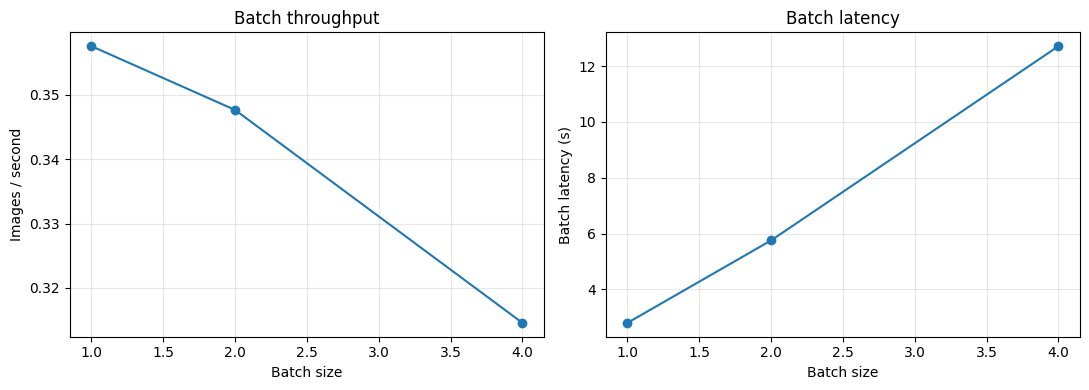

In [5]:
batch_rows=[]; batch_outputs={}
for bs in CONFIG["batch_sizes"]:
    try:
        result=benchmark(pipe,batch_size=int(bs))
        batch_outputs[int(bs)]=result["images"]
        row={"batch_size":int(bs),"latency_s":result["median_seconds"],"per_image_s":result["per_image_seconds"],
             "images_per_s":result["images_per_second"],"peak_allocated_gib":result["peak_allocated_gib"],
             "peak_reserved_gib":result["peak_reserved_gib"],"status":"ok"}
    except (torch.cuda.OutOfMemoryError,RuntimeError) as exc:
        row={"batch_size":int(bs),"latency_s":None,"per_image_s":None,"images_per_s":None,
             "peak_allocated_gib":None,"peak_reserved_gib":None,"status":f"failed: {str(exc)[:140]}"}
        if device.type=="cuda": torch.cuda.empty_cache()
    batch_rows.append(row)
for row in batch_rows: print(row)
valid=[r for r in batch_rows if r["status"]=="ok"]
if valid:
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    axes[0].plot([r["batch_size"] for r in valid],[r["images_per_s"] for r in valid],marker="o")
    axes[0].set(xlabel="Batch size",ylabel="Images / second",title="Batch throughput")
    axes[1].plot([r["batch_size"] for r in valid],[r["latency_s"] for r in valid],marker="o")
    axes[1].set(xlabel="Batch size",ylabel="Batch latency (s)",title="Batch latency")
    for ax in axes: ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 6. Inference-step comparison

Hold model, prompt, seed, dimensions, guidance, and batch size fixed while changing the number of denoiser evaluations. More steps usually add latency; image quality does not improve monotonically with step count, especially for distilled models designed for few steps.

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

...

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

{'steps': 1, 'median_latency_s': 2.125300697000057, 'repetitions': 3}
{'steps': 2, 'median_latency_s': 2.6772258630001033, 'repetitions': 3}
{'steps': 4, 'median_latency_s': 3.7047853540000233, 'repetitions': 3}


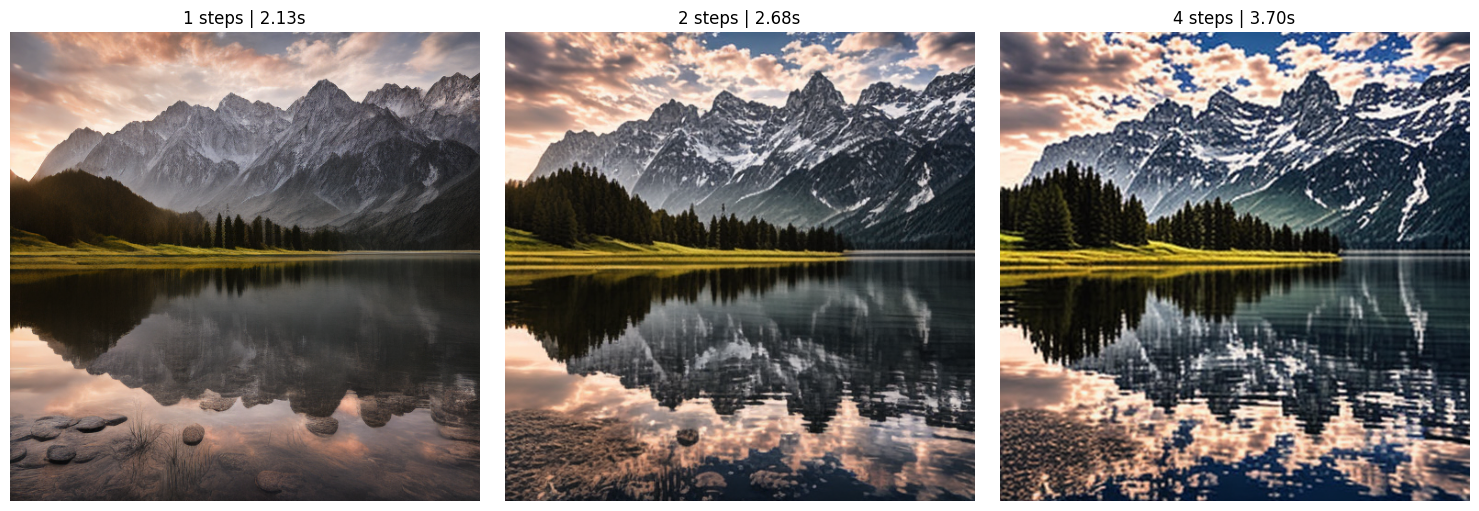

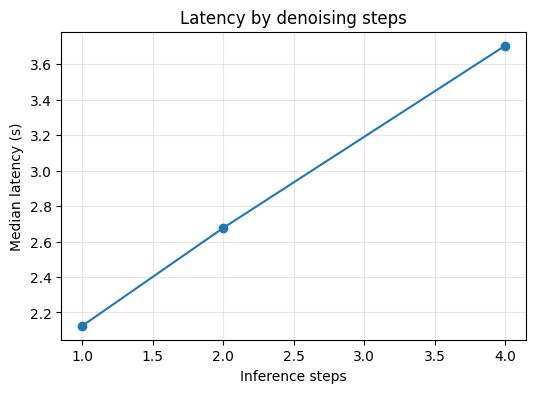

In [6]:
step_rows=[]; step_images=[]
for steps in CONFIG["step_counts"]:
    result=benchmark(pipe,steps=int(steps),batch_size=1)
    step_rows.append({"steps":int(steps),"median_latency_s":result["median_seconds"],"repetitions":result["repetitions"]})
    step_images.append(result["images"][0])
for row in step_rows: print(row)
fig,axes=plt.subplots(1,len(step_rows),figsize=(5*len(step_rows),5),squeeze=False)
for ax,row,img in zip(axes.flat,step_rows,step_images):
    ax.imshow(img); ax.axis("off"); ax.set_title(f"{row['steps']} steps | {row['median_latency_s']:.2f}s")
plt.tight_layout(); plt.show()
plt.figure(figsize=(6,4)); plt.plot([r["steps"] for r in step_rows],[r["median_latency_s"] for r in step_rows],marker="o")
plt.xlabel("Inference steps"); plt.ylabel("Median latency (s)"); plt.title("Latency by denoising steps"); plt.grid(alpha=.3); plt.show()

## 7. Scheduler comparison

The scheduler specifies the reverse trajectory. We compare the checkpoint default with DDIM built from its scheduler configuration. This is a compatibility experiment, not a guarantee that every scheduler is interchangeable with every model. The original scheduler is restored even if conversion or inference fails.

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

{'scheduler': 'EulerDiscreteScheduler', 'median_latency_s': 3.494419228999959, 'status': 'ok'}
{'scheduler': 'DDIMScheduler', 'median_latency_s': 3.349621508999917, 'status': 'ok'}


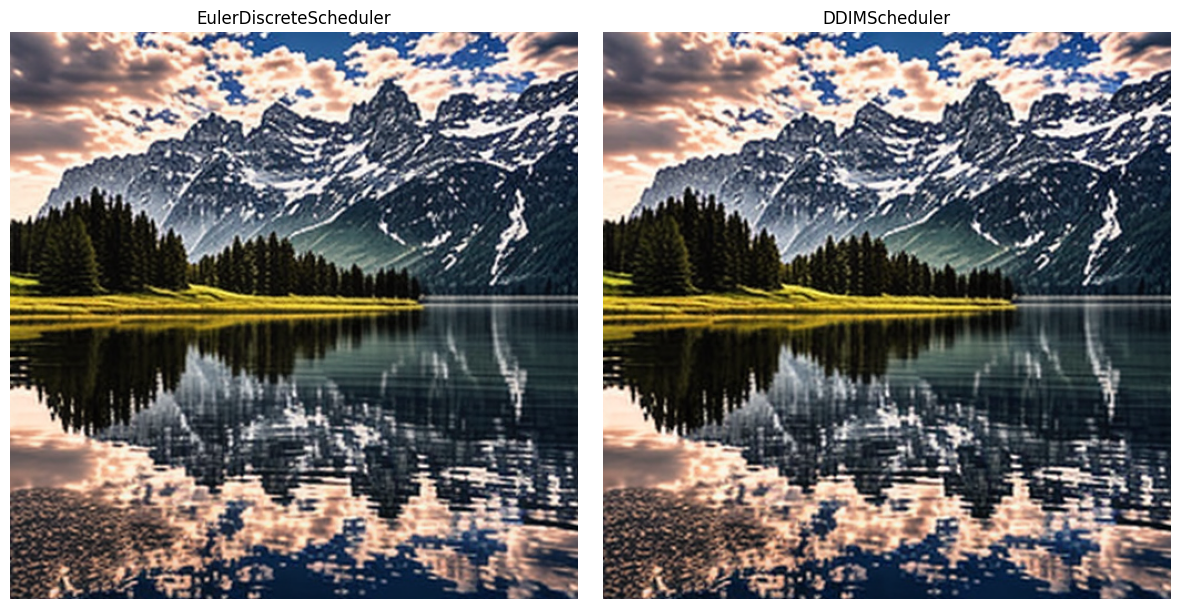

In [7]:
scheduler_rows=[]; scheduler_images=[]
try:
    pipe.scheduler=original_scheduler
    r=benchmark(pipe,steps=CONFIG["num_inference_steps"],batch_size=1)
    scheduler_rows.append({"scheduler":type(original_scheduler).__name__,"median_latency_s":r["median_seconds"],"status":"ok"}); scheduler_images.append(r["images"][0])
    pipe.scheduler=DDIMScheduler.from_config(original_scheduler_config)
    r=benchmark(pipe,steps=CONFIG["num_inference_steps"],batch_size=1)
    scheduler_rows.append({"scheduler":type(pipe.scheduler).__name__,"median_latency_s":r["median_seconds"],"status":"ok"}); scheduler_images.append(r["images"][0])
except Exception as exc:
    scheduler_rows.append({"scheduler":"DDIM alternative","median_latency_s":None,"status":f"unsupported: {exc!r}"})
finally:
    pipe.scheduler=original_scheduler
for row in scheduler_rows: print(row)
if scheduler_images:
    fig,axes=plt.subplots(1,len(scheduler_images),figsize=(6*len(scheduler_images),6),squeeze=False)
    for ax,img,row in zip(axes.flat,scheduler_images,scheduler_rows): ax.imshow(img); ax.axis("off"); ax.set_title(row["scheduler"])
    plt.tight_layout(); plt.show()

## 8. Precision comparison

Run each dtype sequentially: load one pipeline, warm it, benchmark, then delete it before the next load to avoid holding several large copies in VRAM. CUDA FP16 is attempted; BF16 is included only if supported; FP32 is included on CUDA and may fail for memory reasons. CPU uses FP32 only. Results and memory measurements are specific to this model and machine.

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

...

  0%|          | 0/4 [00:00<?, ?it/s]

{'precision': 'FP32', 'load_s': 16.953141518999928, 'median_latency_s': 2.28913220000004, 'peak_allocated_gib': 5.585434436798096, 'peak_reserved_gib': 6.310546875, 'status': 'ok'}
{'precision': 'FP16', 'load_s': 15.065381716000047, 'median_latency_s': 0.5913373040000351, 'peak_allocated_gib': 3.025376796722412, 'peak_reserved_gib': 3.625, 'status': 'ok'}
{'precision': 'BF16', 'load_s': 15.266809770000009, 'median_latency_s': 3.4750956479999786, 'peak_allocated_gib': 3.897812843322754, 'peak_reserved_gib': 5.001953125, 'status': 'ok'}


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


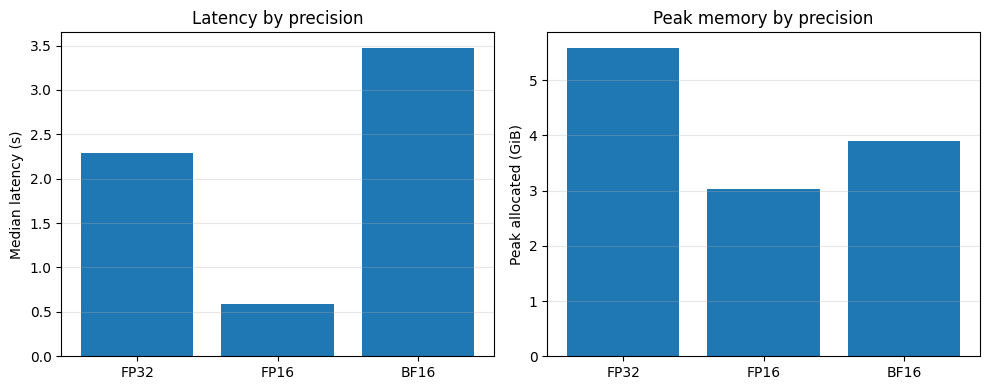

In [8]:
def release_pipeline(obj):
    del obj; gc.collect()
    if device.type=="cuda": torch.cuda.empty_cache()
precision_modes=[("FP32",torch.float32)]
if device.type=="cuda":
    precision_modes.append(("FP16",torch.float16))
    if torch.cuda.is_bf16_supported(): precision_modes.append(("BF16",torch.bfloat16))
precision_rows=[]
# Release the baseline pipeline before loading precision variants.
pipe.scheduler=original_scheduler
pipe=None; gc.collect()
if device.type=="cuda": torch.cuda.empty_cache()
for name,mode in precision_modes:
    candidate=None
    try:
        sync_cuda(); load_t=time.perf_counter(); candidate=load_pipeline(mode); sync_cuda(); load_t=time.perf_counter()-load_t
        res=benchmark(candidate,batch_size=1)
        precision_rows.append({"precision":name,"load_s":load_t,"median_latency_s":res["median_seconds"],
            "peak_allocated_gib":res["peak_allocated_gib"],"peak_reserved_gib":res["peak_reserved_gib"],"status":"ok"})
    except Exception as exc:
        precision_rows.append({"precision":name,"load_s":None,"median_latency_s":None,
            "peak_allocated_gib":None,"peak_reserved_gib":None,"status":f"skipped/failed: {str(exc)[:160]}"})
    finally:
        candidate=None; gc.collect()
        if device.type=="cuda": torch.cuda.empty_cache()
for row in precision_rows: print(row)
# Restore the normal benchmark pipeline and dtype for following sections.
pipe=load_pipeline(BASE_DTYPE); original_scheduler=pipe.scheduler; original_scheduler_config=pipe.scheduler.config
ok_precision=[r for r in precision_rows if r["status"]=="ok"]
if ok_precision:
    fig,axes=plt.subplots(1,2,figsize=(10,4))
    axes[0].bar([r["precision"] for r in ok_precision],[r["median_latency_s"] for r in ok_precision]); axes[0].set(ylabel="Median latency (s)",title="Latency by precision")
    mem=[r["peak_allocated_gib"] for r in ok_precision]
    if all(v is not None for v in mem): axes[1].bar([r["precision"] for r in ok_precision],mem); axes[1].set(ylabel="Peak allocated (GiB)",title="Peak memory by precision")
    for ax in axes: ax.grid(axis="y",alpha=.3)
    plt.tight_layout(); plt.show()

## 9. Memory optimizations

VAE slicing reduces decode activation memory for multi-image batches, often with some overhead. Model CPU offload moves components between CPU and GPU to reduce VRAM, usually at a latency cost. Attention slicing is useful only when the active attention backend does not already use memory-efficient SDPA or xFormers; enabling both can slow inference. This section benchmarks VAE slicing when available. Offload comparison is optional because the extra model load and transfer time can be substantial.

In [9]:
memory_rows=[]
try:
    before=benchmark(pipe,batch_size=2)
    if hasattr(pipe,"enable_vae_slicing"):
        pipe.enable_vae_slicing(); after=benchmark(pipe,batch_size=2)
        memory_rows.append({"option":"VAE slicing","baseline_s":before["median_seconds"],"optimized_s":after["median_seconds"],
            "baseline_peak_allocated_gib":before["peak_allocated_gib"],"optimized_peak_allocated_gib":after["peak_allocated_gib"],"status":"measured"})
        if hasattr(pipe,"disable_vae_slicing"): pipe.disable_vae_slicing()
    else: print("VAE slicing is unavailable in this pipeline class.")
except Exception as exc:
    memory_rows.append({"option":"VAE slicing","status":f"failed: {exc!r}"})

# Attention backend inspection: do not enable slicing on top of SDPA/xFormers.
processors=getattr(getattr(pipe,"unet",None),"attn_processors",{})
processor_names={type(v).__name__ for v in processors.values()} if processors else set()
efficient_backend=any("2_0" in n or "XFormers" in n or "xFormers" in n for n in processor_names)
print("Attention processors:",sorted(processor_names)[:8],"| efficient backend detected:",efficient_backend)
if hasattr(pipe,"enable_attention_slicing") and not efficient_backend:
    try:
        before=benchmark(pipe,batch_size=1); pipe.enable_attention_slicing(); after=benchmark(pipe,batch_size=1)
        memory_rows.append({"option":"attention slicing","baseline_s":before["median_seconds"],"optimized_s":after["median_seconds"],
            "baseline_peak_allocated_gib":before["peak_allocated_gib"],"optimized_peak_allocated_gib":after["peak_allocated_gib"],"status":"measured"})
        if hasattr(pipe,"disable_attention_slicing"): pipe.disable_attention_slicing()
    except Exception as exc: memory_rows.append({"option":"attention slicing","status":f"skipped: {exc!r}"})
else:
    print("Attention slicing not enabled: efficient attention appears active or the method is unavailable.")
for row in memory_rows: print(row)

if CONFIG["run_cpu_offload_experiment"] and device.type=="cuda":
    offload_pipe=None
    try:
        offload_pipe=load_pipeline(BASE_DTYPE,offload=True)
        r=benchmark(offload_pipe,batch_size=1)
        print({"option":"model CPU offload","latency_s":r["median_seconds"],"peak_allocated_gib":r["peak_allocated_gib"]})
    except Exception as exc: print("CPU offload experiment failed:",repr(exc))
    finally:
        if offload_pipe is not None: release_pipeline(offload_pipe)
else:
    print("Model CPU offload experiment skipped. Set run_cpu_offload_experiment=True to measure it on CUDA.")

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

VAE slicing is unavailable in this pipeline class.
Attention processors: ['AttnProcessor2_0'] | efficient backend detected: True
Attention slicing not enabled: efficient attention appears active or the method is unavailable.
Model CPU offload experiment skipped. Set run_cpu_offload_experiment=True to measure it on CUDA.


## 10. Reproducibility and benchmark methodology

The first inference may be slower because of kernel initialization, memory allocation, and cache effects. Warm-up helps isolate steady-state behavior. CUDA launches are asynchronous, so synchronization is needed around wall-clock timing. Download/loading time is measured separately. This notebook reports medians over repeated runs; fixed seeds help control random input but do not guarantee bitwise equality across devices, dtypes, kernels, or library versions. For fair comparisons keep prompt, seed, dimensions, scheduler, steps, batch, and repetition counts fixed. Production request latency also includes queue wait and I/O.

In [10]:
print("Baseline load (download + initialization):",f"{load_seconds:.2f}s")
print("Baseline warm-up runs:",CONFIG["warmup_runs"],"repetitions:",CONFIG["repetitions"])
print("Baseline median generation latency:",f"{baseline['median_seconds']:.3f}s")
print("Benchmark resolution / dtype / device:",f"{CONFIG['width']}x{CONFIG['height']}",BASE_DTYPE,device)

Baseline load (download + initialization): 75.17s
Baseline warm-up runs: 1 repetitions: 3
Baseline median generation latency: 2.723s
Benchmark resolution / dtype / device: 512x512 torch.bfloat16 cuda


## 11. Deployment design and optional FastAPI example

A practical service loads one pipeline during application startup and keeps it resident. Validate prompts, dimensions, steps, and batch size; cap outputs; bound the request queue and return backpressure when full. One GPU worker avoids uncontrolled simultaneous generation. Set request and queue timeouts, but cancellation may not stop a CUDA kernel already running. Encode images efficiently and limit response size. Log queue time, generation time, failures, and memory. Add authentication, rate limits, usage quotas, and cost controls. Check model licensing and deployment terms.

The optional example below is illustrative code only; it does not start a server in the notebook. It uses one bounded queue and one worker. Save the cell as `app.py` in a separate deployment environment, install its dependencies, and launch separately with `uvicorn app:app`. Synchronous GPU work is serialized here; it will not automatically scale under concurrent traffic.

In [11]:
# Optional FastAPI service example. This cell defines an app; it does not launch a server.
from contextlib import asynccontextmanager
from fastapi import FastAPI, HTTPException
from fastapi.responses import StreamingResponse
from pydantic import BaseModel, Field

API_QUEUE_LIMIT=4
API_MAX_DIMENSION=512
API_MAX_STEPS=4
api_queue=None
api_pipeline=None

class GenerateRequest(BaseModel):
    prompt:str=Field(min_length=1,max_length=1200)
    seed:int=2026
    steps:int=Field(default=4,ge=1,le=API_MAX_STEPS)
    width:int=Field(default=512,ge=256,le=API_MAX_DIMENSION)
    height:int=Field(default=512,ge=256,le=API_MAX_DIMENSION)

@asynccontextmanager
async def lifespan(app):
    global api_queue,api_pipeline
    api_pipeline=load_pipeline(BASE_DTYPE)
    api_queue=asyncio.Queue(maxsize=API_QUEUE_LIMIT)
    worker=asyncio.create_task(api_worker())
    yield
    worker.cancel()
    try: await worker
    except asyncio.CancelledError: pass
    api_pipeline=None

app=FastAPI(title="Diffusion inference demo",lifespan=lifespan)

async def api_worker():
    while True:
        request,future=await api_queue.get()
        try:
            if future.cancelled(): continue
            image=await asyncio.to_thread(api_generate_image,request)
            if not future.cancelled(): future.set_result(image)
        except Exception as exc:
            if not future.cancelled(): future.set_exception(exc)
        finally: api_queue.task_done()

def api_generate_image(request:GenerateRequest)->bytes:
    args={"prompt":request.prompt,"height":request.height,"width":request.width,
          "num_inference_steps":request.steps,"guidance_scale":0.0,
          "generator":torch.Generator(device=device).manual_seed(request.seed)}
    with torch.inference_mode(): image=api_pipeline(**args).images[0]
    buffer=io.BytesIO(); image.save(buffer,format="PNG"); return buffer.getvalue()

@app.get("/health")
async def health(): return {"status":"ok","model_id":CONFIG["MODEL_ID"]}

@app.post("/generate")
async def api_generate(request:GenerateRequest):
    if request.width%8 or request.height%8:
        raise HTTPException(status_code=422,detail="Width and height must be divisible by 8.")
    if api_queue is None: raise HTTPException(status_code=503,detail="Model is starting.")
    future=asyncio.get_running_loop().create_future()
    try: api_queue.put_nowait((request,future))
    except asyncio.QueueFull: raise HTTPException(status_code=429,detail="Generation queue is full; retry later.")
    try:
        png=await asyncio.wait_for(future,timeout=120)
    except asyncio.TimeoutError:
        future.cancel()
        raise HTTPException(status_code=504,detail="Generation timed out. A running GPU call may still finish in the worker.")
    except Exception as exc: raise HTTPException(status_code=500,detail=f"Generation failed: {exc}")
    return StreamingResponse(io.BytesIO(png),media_type="image/png")

print("FastAPI app defined. To run separately: uvicorn app:app --host 0.0.0.0 --port 8000")

FastAPI app defined. To run separately: uvicorn app:app --host 0.0.0.0 --port 8000


## 12. Conclusions and exercises

Choose settings based on measured latency, throughput, peak memory, and visual inspection on your actual hardware. No precision, batch size, scheduler, or step count is universally fastest or best. Keep cold-start/download time separate from warm generation and end-to-end request latency.

Try these experiments:

1. Find the fastest configuration that fits the available GPU memory.
2. Compare latency and throughput across batch sizes.
3. Compare FP16 and FP32 when supported.
4. Compare schedulers and inference-step counts.
5. Recommend a deployment configuration based on measured results, including queue limits and request timeouts.

Benchmark values in this notebook are calculated only when cells run; none are prefilled or claimed.